# DMS ranking-resolution figures: HMC count-based analysis

This notebook composes 49 HMC count-based analyses from tidy tables generated by `summarize.py` and `summarize_mechanisms.py` under `output/hmc_count_based/tables`. For each paired HMC posterior and posterior-predictive draw, the fitness proxy is recomputed from the predictive counts. The sampled distributions therefore combine posterior parameter uncertainty with stochastic count-realization variability. PDZ uses the provisional `dimsum_fitness` proxy, TrpB uses verified `johnston_fitness`, and NucB uses verified generation-specific `highest_gate_enrichment`. Figure 5 and the Figure 6.1--6.3 renderer comparison remain exploratory views.

In [4]:
import importlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

HERE = Path.cwd()
if (HERE / "examples" / "paper" / "figures.py").is_file():
    HERE = HERE / "examples" / "paper"
if not (HERE / "figures.py").is_file():
    raise FileNotFoundError(
        "Run this notebook from the repository or examples/paper directory."
    )
sys.path.insert(0, str(HERE))

import figures

importlib.reload(figures)
from figures import (
    figure_count_rank_uncertainty_by_analysis,
    figure_count_score_uncertainty_by_analysis,
    figure_count_uncertainty_datashader,
    figure_count_uncertainty_hexbin,
    figure_count_uncertainty_scatter,
    figure_fitness_uncertainty_by_analysis,
    figure_functionality_distributions,
    figure_rank_space_sensitivity,
    figure_rank_uncertainty,
    figure_ranking_mechanisms,
    figure_reported_order,
    figure_top_k_stability,
    load_functionality_scores,
    load_mechanism_tables,
    load_tables,
    save_figure,
    set_paper_style,
)

TABLE_DIR = HERE / "output" / "hmc_count_based" / "tables"
FIGURE_DIR = HERE / "output" / "hmc_count_based" / "figures"
MAIN_K = 100
REPRESENTATIVE_IDS = (
    "pdz__pdz-cis__hmc-count-based__lomax-exponential__small-clean-3",
    "trpb__trpb-libd__hmc-count-based__gamma-exponential__small-clean-21",
    "nuc__nuc-g1__hmc-count-based__exponential__small-clean-55",
)

set_paper_style()
tables = load_tables(TABLE_DIR)
inventory = tables["inventory"].sort_values("analysis_order")
reference_diagnostics = pd.read_csv(TABLE_DIR / "reference_diagnostics.csv")
reference_category_sensitivity = pd.read_csv(
    TABLE_DIR / "reference_category_sensitivity.csv"
)
mechanism_diagnostics = pd.read_csv(TABLE_DIR / "mechanism_diagnostics.csv")

assert len(inventory) == 49
assert inventory.groupby("protein_family").size().to_dict() == {
    "pdz": 14,
    "trpb": 28,
    "nuc": 7,
}
assert inventory["landscape"].nunique() == 18
assert set(inventory["inference_method"]) == {"hmc_count_based"}
assert set(REPRESENTATIVE_IDS) <= set(inventory["analysis_id"])
display(inventory)

,analysis_order,analysis_id,source_analysis_id,protein_family,landscape,inference_method,model_spec,fit_id,job_id,artifact_kind,...,score,n_samples,n_variants,n_fitted_variants,n_excluded_from_ranking,retained_k,tracked_reported_top_n,tracked_model_top_n,artifact_status,warnings
0,0,pdz__pdz-trans-1__hmc-count-based__exponential...,pdz__pdz-trans-1__hmc-count-based__exponential...,pdz,pdz-trans-1,hmc_count_based,exponential-exponential,large-clean_82,82,raw_hmc,...,dimsum_fitness,16000,109376,150769,41393,1000,1000,100,validated,"[""This raw-count approximation does not exactl..."
1,1,pdz__pdz-trans-1__hmc-count-based__gamma-expon...,pdz__pdz-trans-1__hmc-count-based__gamma-expon...,pdz,pdz-trans-1,hmc_count_based,gamma-exponential,large-clean_84,84,diagnosed_hmc,...,dimsum_fitness,16000,109376,150769,41393,1000,1000,100,validated,"[""This raw-count approximation does not exactl..."
2,2,pdz__pdz-trans-2__hmc-count-based__exponential...,pdz__pdz-trans-2__hmc-count-based__exponential...,pdz,pdz-trans-2,hmc_count_based,exponential-exponential,large-clean_88,88,diagnosed_hmc,...,dimsum_fitness,16000,142251,151624,9373,1000,1000,100,validated,"[""This raw-count approximation does not exactl..."
3,3,pdz__pdz-trans-2__hmc-count-based__gamma-sigmo...,pdz__pdz-trans-2__hmc-count-based__gamma-sigmo...,pdz,pdz-trans-2,hmc_count_based,gamma-sigmoid,large-clean_93,93,diagnosed_hmc,...,dimsum_fitness,16000,142251,151624,9373,1000,1000,100,validated,"[""This raw-count approximation does not exactl..."
4,4,pdz__pdz-cis__hmc-count-based__exponential-exp...,pdz__pdz-cis__hmc-count-based__exponential-exp...,pdz,pdz-cis,hmc_count_based,exponential-exponential,small-clean_1,1,diagnosed_hmc,...,dimsum_fitness,16000,9475,10660,1185,1000,1000,100,validated,"[""This raw-count approximation does not exactl..."
5,5,pdz__pdz-cis__hmc-count-based__lomax-exponenti...,pdz__pdz-cis__hmc-count-based__lomax-exponenti...,pdz,pdz-cis,hmc_count_based,lomax-exponential,small-clean_3,3,diagnosed_hmc,...,dimsum_fitness,16000,9475,10660,1185,1000,1000,100,validated,"[""This raw-count approximation does not exactl..."
6,6,pdz__pdz-cis__hmc-count-based__exponential-sig...,pdz__pdz-cis__hmc-count-based__exponential-sig...,pdz,pdz-cis,hmc_count_based,exponential-sigmoid,small-clean_4,4,diagnosed_hmc,...,dimsum_fitness,16000,9475,10660,1185,1000,1000,100,validated,"[""This raw-count approximation does not exactl..."
7,7,pdz__pdz-cript-c__hmc-count-based__exponential...,pdz__pdz-cript-c__hmc-count-based__exponential...,pdz,pdz-cript-c,hmc_count_based,exponential-exponential,large-clean_70,70,diagnosed_hmc,...,dimsum_fitness,16000,117723,145290,27567,1000,1000,100,validated,"[""This raw-count approximation does not exactl..."
8,8,pdz__pdz-cript-c__hmc-count-based__lomax-expon...,pdz__pdz-cript-c__hmc-count-based__lomax-expon...,pdz,pdz-cript-c,hmc_count_based,lomax-exponential,large-clean_71,71,raw_hmc,...,dimsum_fitness,24000,117723,145290,27567,1000,1000,100,validated,"[""This raw-count approximation does not exactl..."
9,9,pdz__pdz-cript-c__hmc-count-based__gamma-expon...,pdz__pdz-cript-c__hmc-count-based__gamma-expon...,pdz,pdz-cript-c,hmc_count_based,gamma-exponential,large-clean_72,72,raw_hmc,...,dimsum_fitness,24000,117723,145290,27567,1000,1000,100,validated,"[""This raw-count approximation does not exactl..."


## Figure 1: Reported ordering

Panels (a)--(d) show where each published top-100 rank falls in its sampled count-proxy rank distribution for one representative analysis per family. Panel (e) reports the directional ECDF-to-uniform area. Panel (f) reports Spearman correlation between published rank and the median HMC count-proxy rank. Positive values indicate concordant ordering; negative values indicate reversal.

The published comparator and sampled score have the same assay-level definition for TrpB and NucB. PDZ compares published DiMSum output with the repository's provisional DiMSum-style count proxy, whose scale and procedure are not an exact source reconstruction.

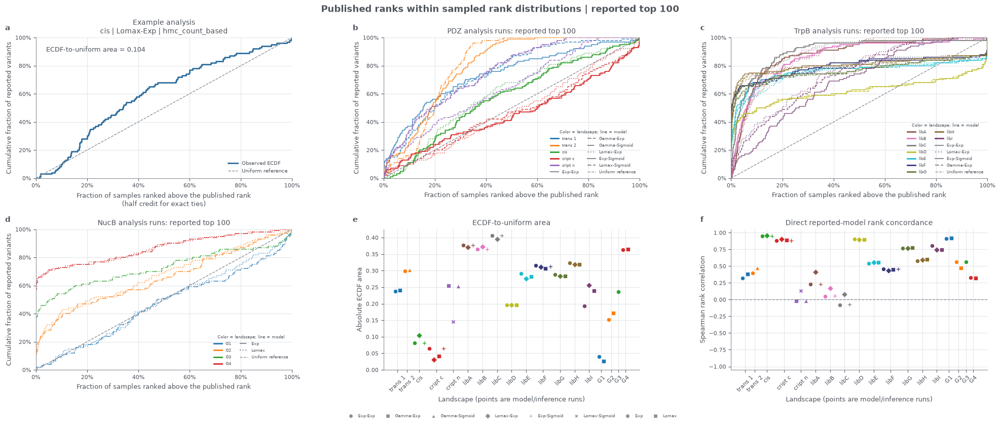

In [2]:
figure_1 = figure_reported_order(
    tables,
    cohort_top_n=MAIN_K,
    example_id=REPRESENTATIVE_IDS[0],
)
display(figure_1)
save_figure(figure_1, FIGURE_DIR, "figure1_reported_order")
plt.close(figure_1)

## Figure 2: Rank uncertainty

The first row contains one representative analysis per protein family and shows count-proxy reference ranks 1--50 in raw rank positions. Each label begins with its reference rank. The pale line is the 5th--95th percentile rank interval across paired HMC posterior-predictive draws, the blue circle is the median sampled rank, and the green diamond is the published rank. The lower panels summarize interval widths among each run's reference top 100 and the fraction whose 95th-percentile sampled rank exceeds 100.

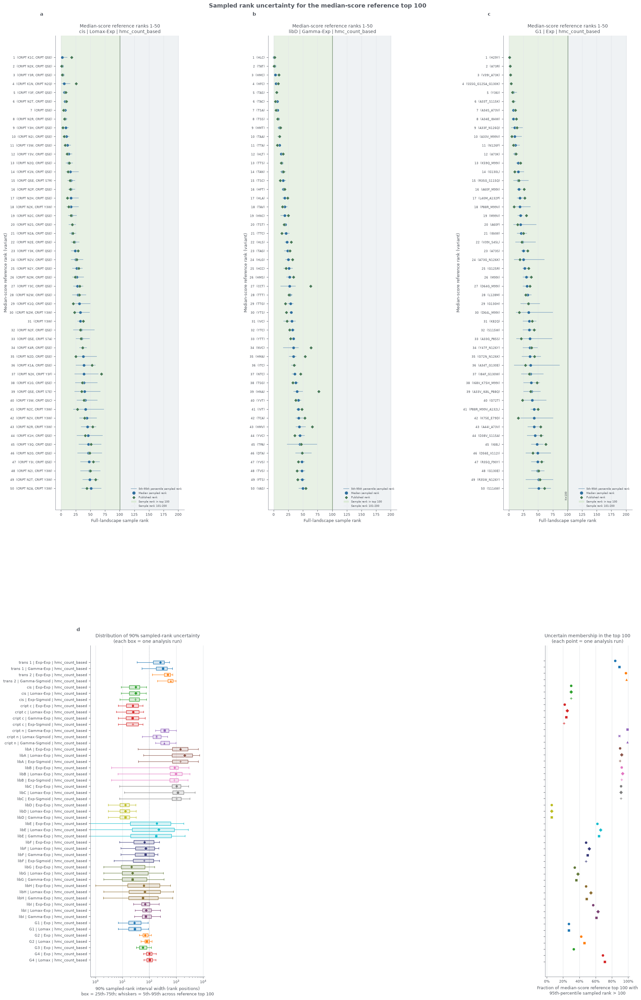

In [3]:
figure_2 = figure_rank_uncertainty(
    tables,
    representative_ids=REPRESENTATIVE_IDS,
    main_k=MAIN_K,
)
display(figure_2)
save_figure(figure_2, FIGURE_DIR, 'figure2_rank_uncertainty')
plt.close(figure_2)

## Figure 3: Top-K decision stability

The top row contains one representative analysis per protein family and shows median count-proxy reference ranks 91--100 plus the ten strongest outside challengers. The bottom row evaluates each family at `K = 1, 2, 5, 10, 20, 50, 100, 200, 500, 1000`. Blue compares two sampled top-K sets, orange compares sampled top-K with the median count-proxy reference set, and green compares sampled top-K with the published set. Thin curves are individual analyses; thick curves first combine fitted models within each landscape and then take the median across landscapes.

These curves measure stability of the count-derived decision under the joint posterior-predictive distribution. They do not isolate posterior parameter uncertainty from the additional variation introduced by drawing new sequencing counts.

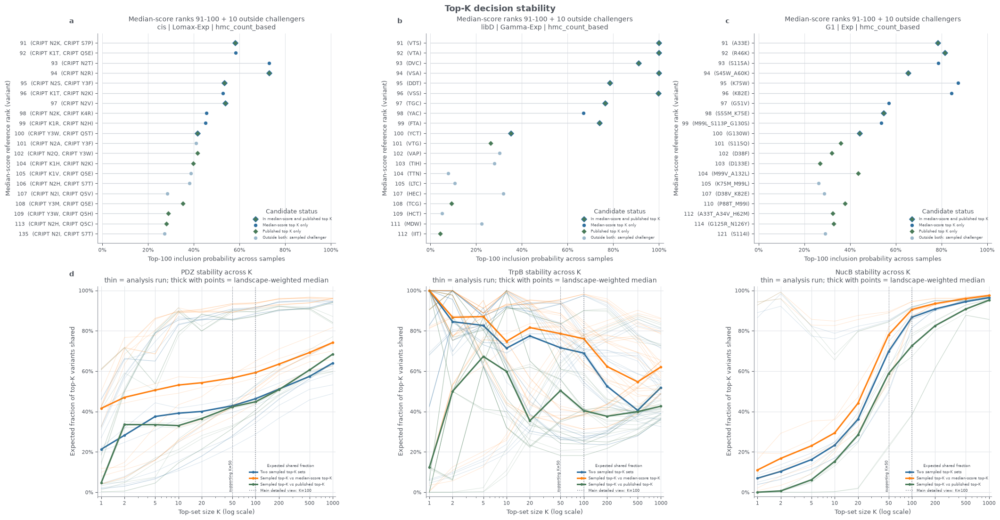

In [4]:
figure_3 = figure_top_k_stability(
    tables,
    representative_ids=REPRESENTATIVE_IDS,
    main_k=MAIN_K,
)
display(figure_3)
save_figure(figure_3, FIGURE_DIR, 'figure3_top_k_stability')
plt.close(figure_3)

## Mechanism-table boundary

Figures 1--3 use the compact stability bundles directly. Figures 4--10 use mechanism tables because they additionally require median count-proxy scores for every ranking-eligible candidate and complete score/rank trajectories for challengers identified after top-100 inclusion probabilities were known. The mechanism builder rereads the persisted HMC count-proxy matrices; it does not rerun HMC or regenerate counts. NucB source controls remain in the fitted normalization universe but are excluded from every ranking cohort.

## Figure 4: From experimental support to ranking resolution

For variant $i$, let the normalized central 90% score width be

$$
U_i=\frac{Q_{0.95}(z_i)-Q_{0.05}(z_i)}{S_{\mathrm{run}}},
$$

where $z_i$ is the count-derived proxy and $S_{\mathrm{run}}$ is the IQR of median proxy scores among the reference top 1,000. Let

$$
W_i^R=Q_{0.95}(R_i)-Q_{0.05}(R_i)
$$

be its sampled-rank interval width. The primary cohort is the reference top 100 plus outside variants with at least 1% sampled top-100 inclusion probability.

Panel (a) relates within-run input-support deciles to $U_i$. Panel (b) relates within-run score-uncertainty deciles to $W_i^R$. Panels (c) and (d) compare two same-run neighborhoods with similar focal score uncertainty but different local median-score spacing. Thin curves are analyses; bold curves first aggregate fitted models within landscape and then landscapes within family. These are descriptive posterior-predictive associations, not estimates of the causal effect of adding reads.

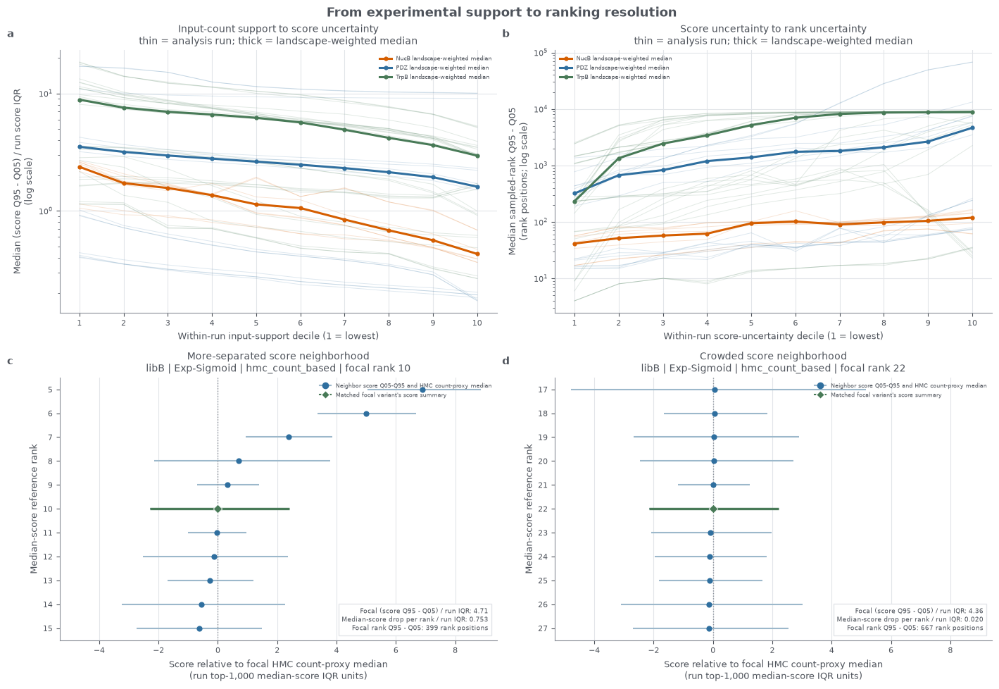

In [5]:
mechanism_tables = load_mechanism_tables(TABLE_DIR)
figure_4 = figure_ranking_mechanisms(mechanism_tables)
display(figure_4)
save_figure(figure_4, FIGURE_DIR, "figure4_ranking_mechanisms")
plt.close(figure_4)

## Figure 5: Temporary rank-space sensitivity view

This sensitivity view shows the Figure 4 relationships directly in rank positions. Panel (a) bins the primary cohort by within-run input support and plots median central 90% sampled-rank width. Panel (b) bins by raw central 90% count-proxy width and again plots rank width. Panels (c) and (d) compare deterministic ten-variant windows with relatively separated versus strongly overlapping sampled-rank intervals.

The figure remains descriptive. It does not separate parameter uncertainty from predictive count noise and does not substitute for count downsampling followed by refitting.

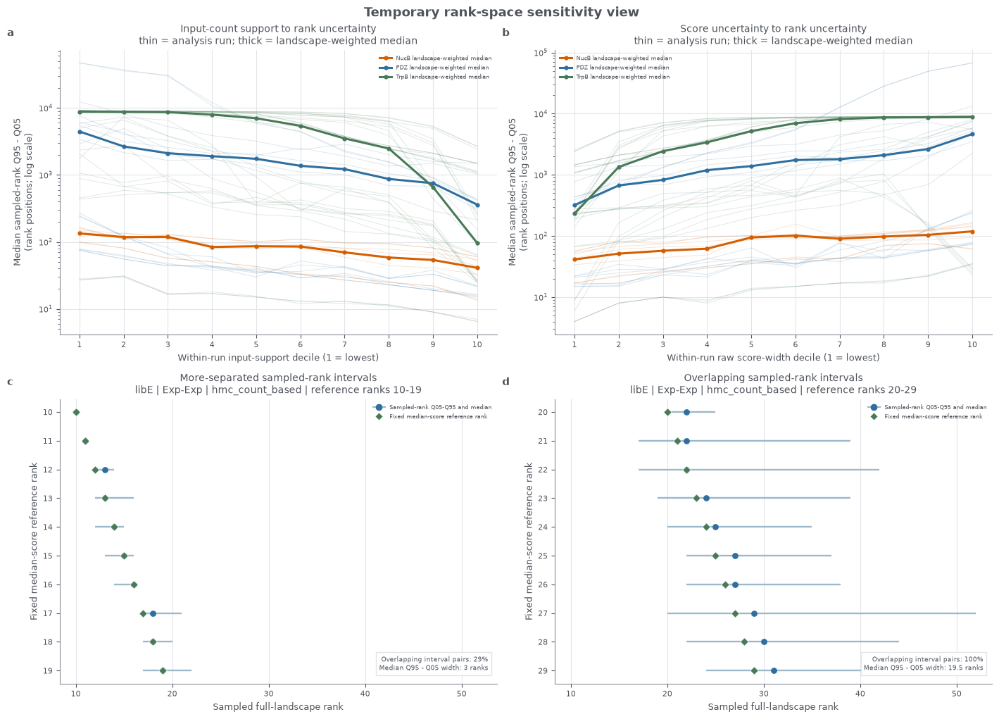

In [6]:
figure_5 = figure_rank_space_sensitivity(mechanism_tables)
display(figure_5)
save_figure(figure_5, FIGURE_DIR, "figure5_rank_space_sensitivity")
plt.close(figure_5)

## Figures 6.1–6.3: Variant-level count support and proxy uncertainty

These exploratory figures show the same relationships with standard scatter, Datashader, and hexagonal-bin rendering. Inputs are the tracked run-variant rows in `mechanism_variants.csv`, not every raw-table variant. A biological variant can appear once per fitted model, so rows are not independent biological replicates.

The four panels compare observed input or output count with normalized count-proxy or rank uncertainty. Counts use $\log_{10}(n+1)$ so zeros are retained. Color identifies landscape and marker shape identifies model family where individual points are visible. Dark lines are pooled descriptive least-squares trends, not landscape-balanced estimates or inferential regressions.

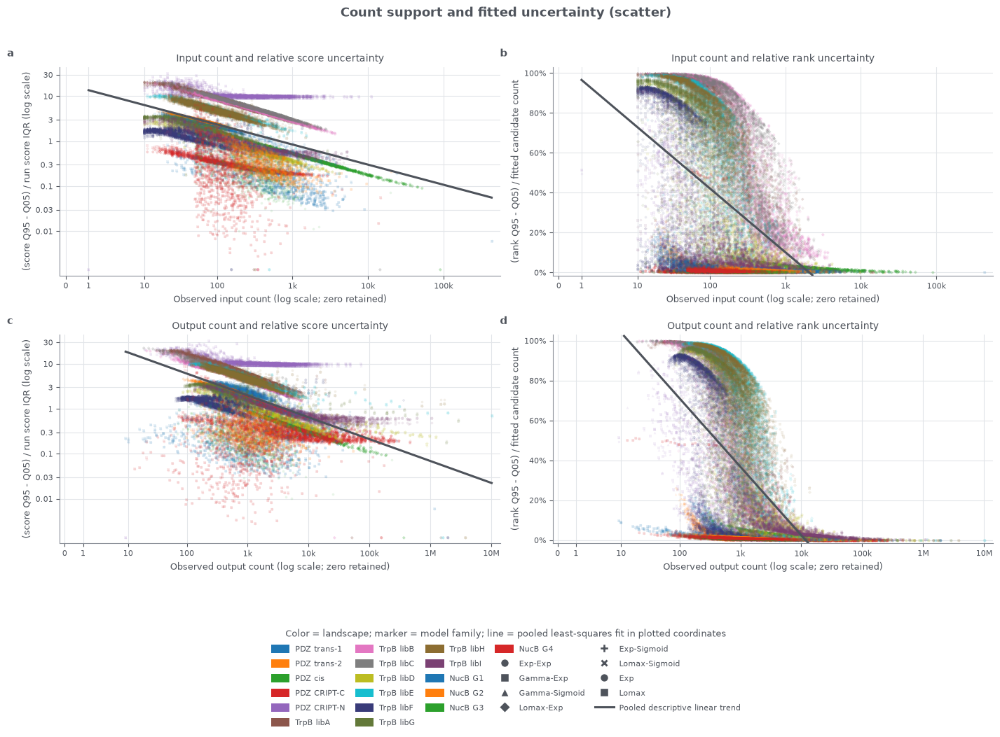

In [7]:
figure_6_1 = figure_count_uncertainty_scatter(mechanism_tables)
display(figure_6_1)
save_figure(
    figure_6_1,
    FIGURE_DIR,
    "figure6_1_count_uncertainty_scatter",
)
plt.close(figure_6_1)

### Figure 6.2: Datashader density

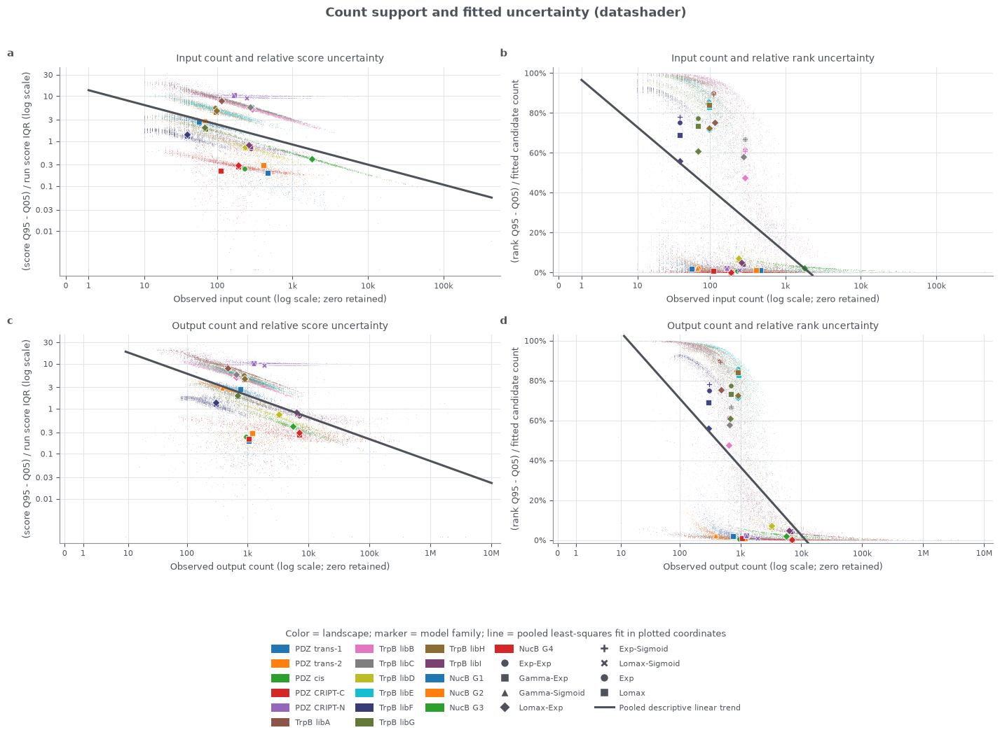

In [8]:
figure_6_2 = figure_count_uncertainty_datashader(mechanism_tables)
display(figure_6_2)
save_figure(
    figure_6_2,
    FIGURE_DIR,
    "figure6_2_count_uncertainty_datashader",
)
plt.close(figure_6_2)

### Figure 6.3: Hexagonal-bin density

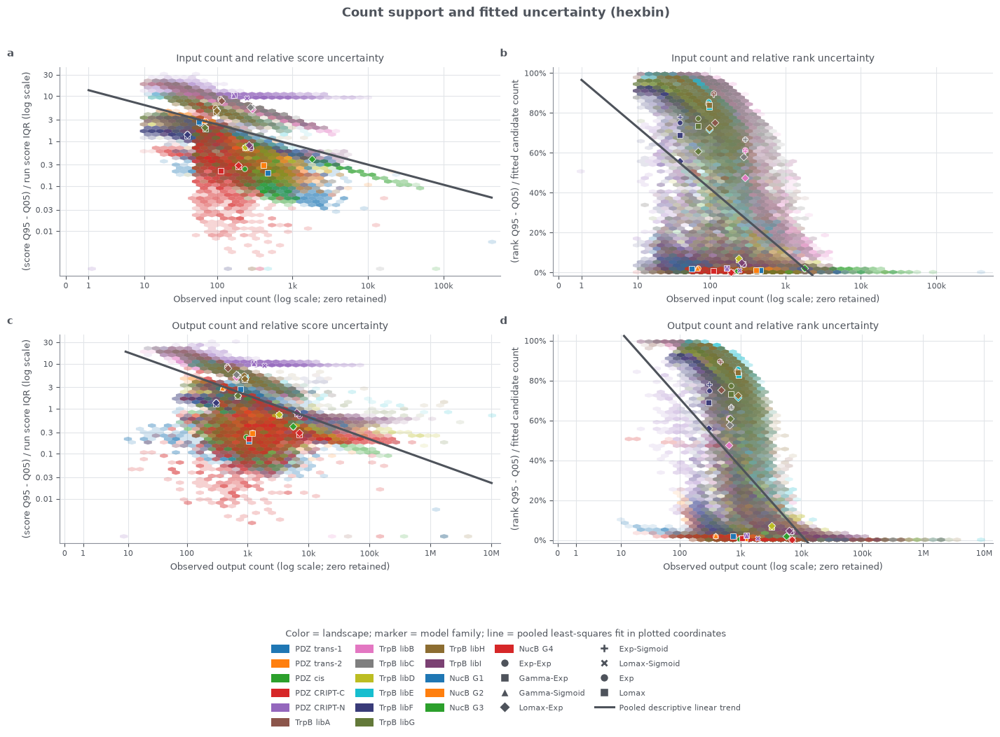

In [9]:
figure_6_3 = figure_count_uncertainty_hexbin(mechanism_tables)
display(figure_6_3)
save_figure(
    figure_6_3,
    FIGURE_DIR,
    "figure6_3_count_uncertainty_hexbin",
)
plt.close(figure_6_3)

## Figures 7.1–7.2: Count support and uncertainty within each analysis

These temporary figures separate the pooled Figure 6 relationships into one row per analysis run. Each row uses every tracked run–variant row for that analysis, with input count on the left and output count on the right. Counts retain zero through $\log_{10}(n+1)$.

Figures **7.1.pdz**, **7.1.trpb**, and **7.1.nucb** plot relative score uncertainty,

$$
\frac{Q_{0.95}(z_i)-Q_{0.05}(z_i)}{S_{\mathrm{run}}}.
$$

Figures **7.2.pdz**, **7.2.trpb**, and **7.2.nucb** plot relative rank uncertainty,

$$
\frac{Q_{0.95}(R_i)-Q_{0.05}(R_i)}{N_{\mathrm{candidates}}}.
$$

All rows within one figure share the same input-count scale, output-count scale, and uncertainty scale, so patterns can be compared directly across analyses for that protein family. Each dark line is fit only to the variants in that row and panel. It is a descriptive least-squares line in the plotted coordinates, not an inferential or causal estimate. Color identifies landscape and marker shape identifies model family; the analysis label is also printed above the left panel of every row.

### Figure 7.1.pdz: Relative score uncertainty by PDZ analysis

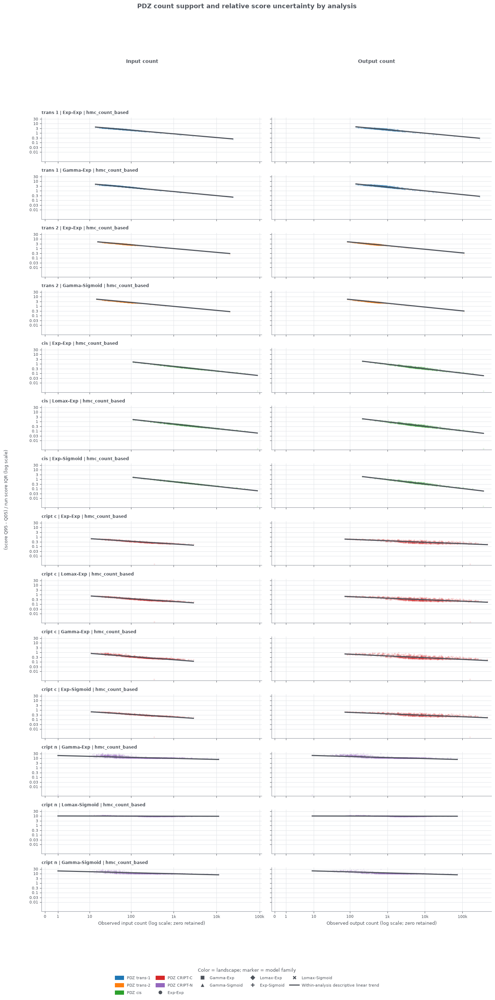

In [10]:
figure_7_1_pdz = figure_count_score_uncertainty_by_analysis(
    mechanism_tables,
    protein_family="pdz",
)
display(figure_7_1_pdz)
save_figure(
    figure_7_1_pdz,
    FIGURE_DIR,
    "figure7_1_pdz_by_analysis",
)
plt.close(figure_7_1_pdz)

### Figure 7.1.trpb: Relative score uncertainty by TrpB analysis

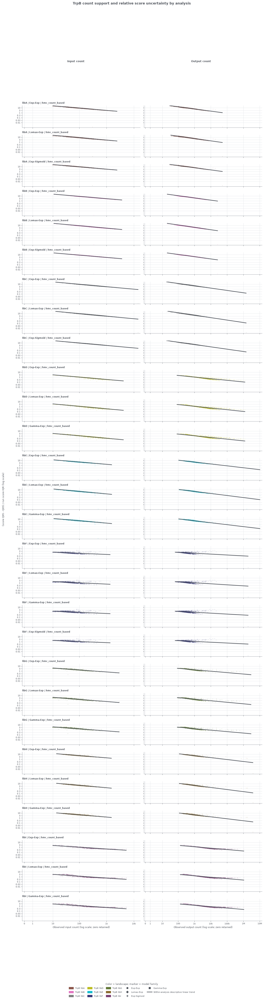

In [11]:
figure_7_1_trpb = figure_count_score_uncertainty_by_analysis(
    mechanism_tables,
    protein_family="trpb",
)
display(figure_7_1_trpb)
save_figure(
    figure_7_1_trpb,
    FIGURE_DIR,
    "figure7_1_trpb_by_analysis",
)
plt.close(figure_7_1_trpb)

### Figure 7.1.nucb: Relative score uncertainty by NucB analysis

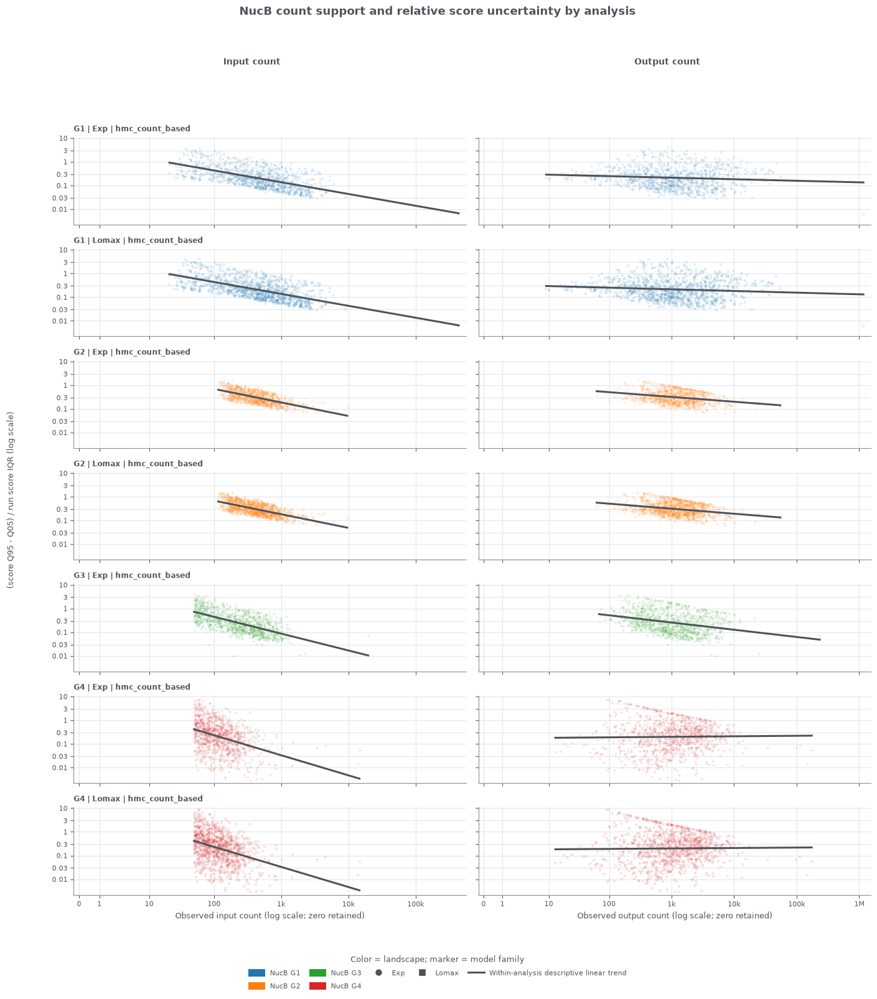

In [12]:
figure_7_1_nuc = figure_count_score_uncertainty_by_analysis(
    mechanism_tables,
    protein_family="nuc",
)
display(figure_7_1_nuc)
save_figure(
    figure_7_1_nuc,
    FIGURE_DIR,
    "figure7_1_nucb_by_analysis",
)
plt.close(figure_7_1_nuc)

### Figure 7.2.pdz: Relative rank uncertainty by PDZ analysis

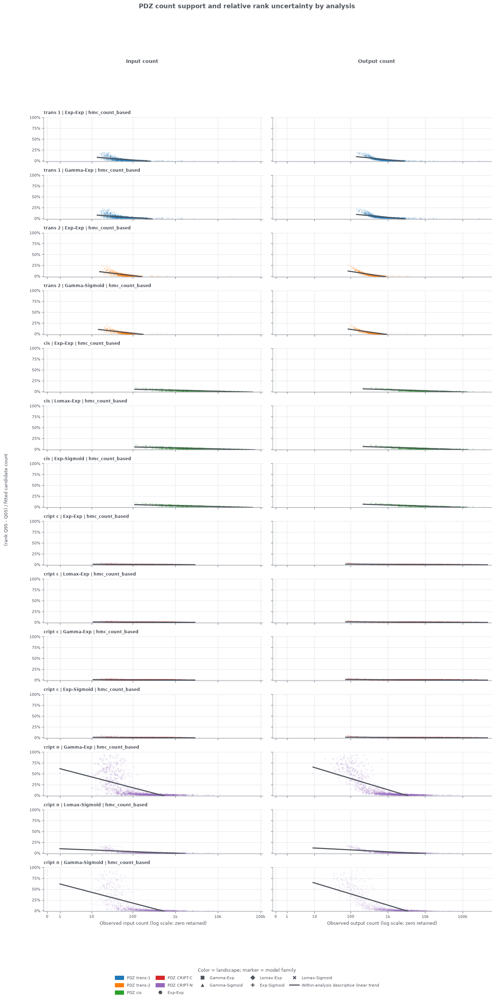

In [13]:
figure_7_2_pdz = figure_count_rank_uncertainty_by_analysis(
    mechanism_tables,
    protein_family="pdz",
)
display(figure_7_2_pdz)
save_figure(
    figure_7_2_pdz,
    FIGURE_DIR,
    "figure7_2_pdz_by_analysis",
)
plt.close(figure_7_2_pdz)

### Figure 7.2.trpb: Relative rank uncertainty by TrpB analysis

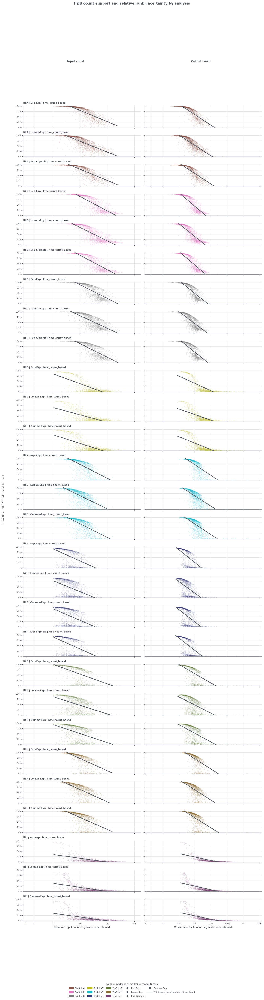

In [14]:
figure_7_2_trpb = figure_count_rank_uncertainty_by_analysis(
    mechanism_tables,
    protein_family="trpb",
)
display(figure_7_2_trpb)
save_figure(
    figure_7_2_trpb,
    FIGURE_DIR,
    "figure7_2_trpb_by_analysis",
)
plt.close(figure_7_2_trpb)

### Figure 7.2.nucb: Relative rank uncertainty by NucB analysis

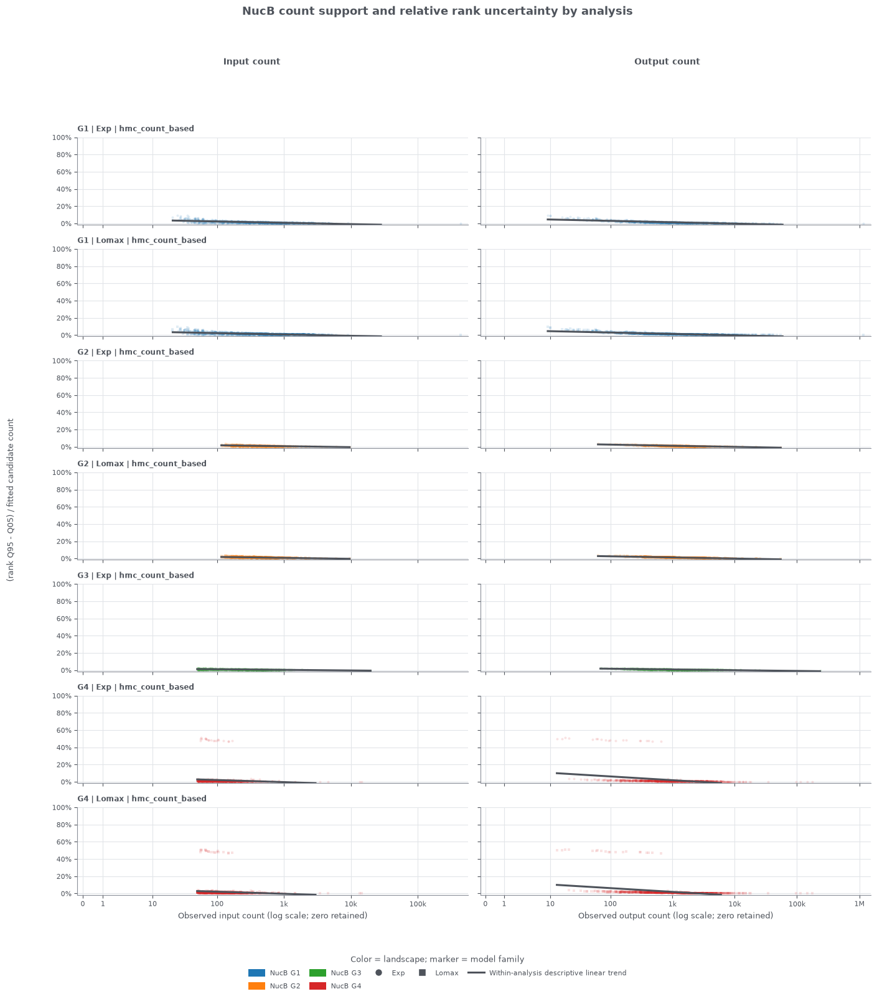

In [15]:
figure_7_2_nuc = figure_count_rank_uncertainty_by_analysis(
    mechanism_tables,
    protein_family="nuc",
)
display(figure_7_2_nuc)
save_figure(
    figure_7_2_nuc,
    FIGURE_DIR,
    "figure7_2_nucb_by_analysis",
)
plt.close(figure_7_2_nuc)

## Figure 8: Median count-proxy geometry

This exploratory view treats the distribution of median count-derived scores as one aspect of landscape functionality. For candidate $i$, let

$$
m_i = Q_{0.50}(z_i),
$$

where $z_i$ is `dimsum_fitness` for PDZ, `johnston_fitness` for TrpB, or `highest_gate_enrichment` for NucB. Each panel is one experimental landscape. Within a panel, every fitted model is shown as a Gaussian KDE of $m_i$ over ranking-eligible candidates, using SciPy's Scott-rule bandwidth. The model-specific vertical line is the score at fixed median-proxy reference rank 100; that model's top 100 lies to its right. Curves and cutoffs use the same model style. All panels within one protein-family figure share score and density limits.

This figure shows between-candidate geometry in each count-proxy ordering; it does not separate the two sources of posterior-predictive variability. The term *functionality* is operational here and does not imply an experimentally validated binary classification.

### Figure 8.1: PDZ landscapes

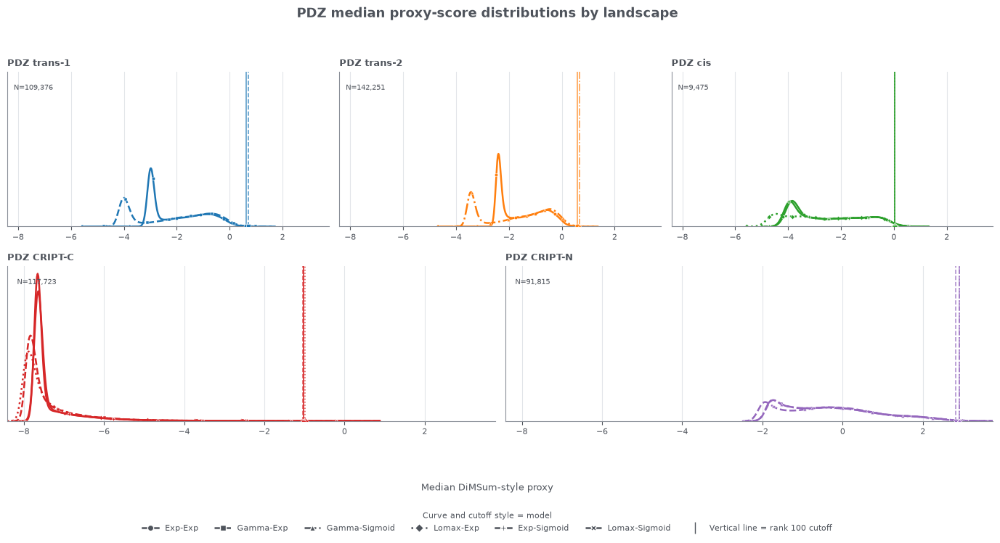

In [16]:
functionality_scores = load_functionality_scores(TABLE_DIR)
figure_8_1_pdz = figure_functionality_distributions(
    inventory,
    functionality_scores,
    protein_family="pdz",
    top_k=MAIN_K,
)
display(figure_8_1_pdz)
save_figure(
    figure_8_1_pdz,
    FIGURE_DIR,
    "figure8_pdz_functionality",
)
plt.close(figure_8_1_pdz)

### Figure 8.2: TrpB landscapes

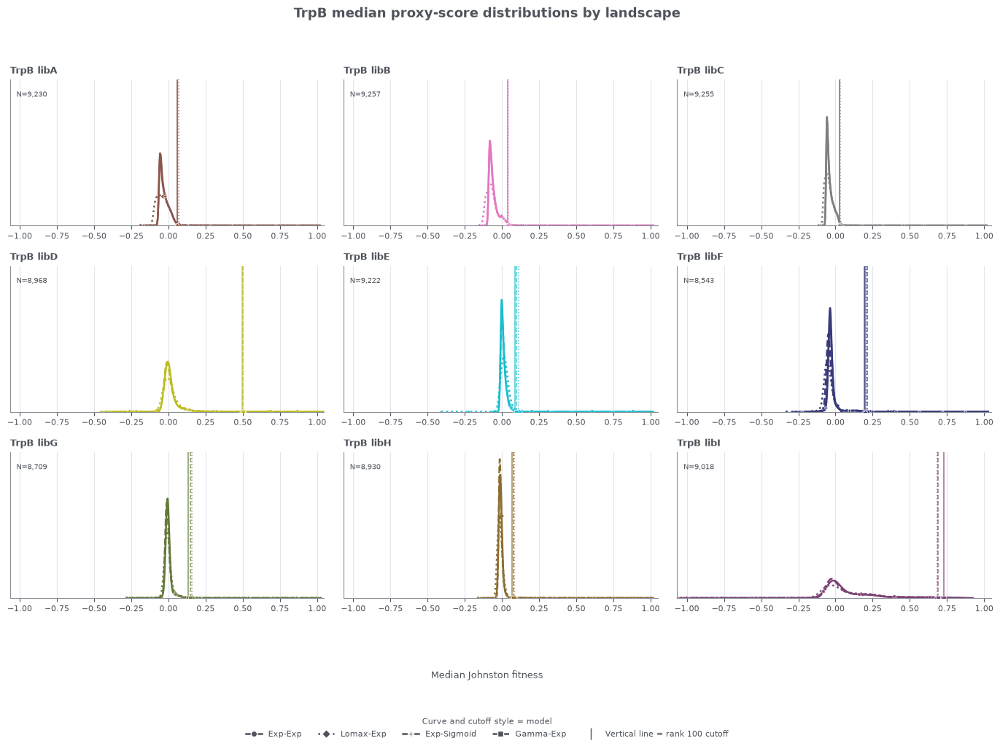

In [17]:
figure_8_2_trpb = figure_functionality_distributions(
    inventory,
    functionality_scores,
    protein_family="trpb",
    top_k=MAIN_K,
)
display(figure_8_2_trpb)
save_figure(
    figure_8_2_trpb,
    FIGURE_DIR,
    "figure8_trpb_functionality",
)
plt.close(figure_8_2_trpb)

### Figure 8.3: NucB landscapes

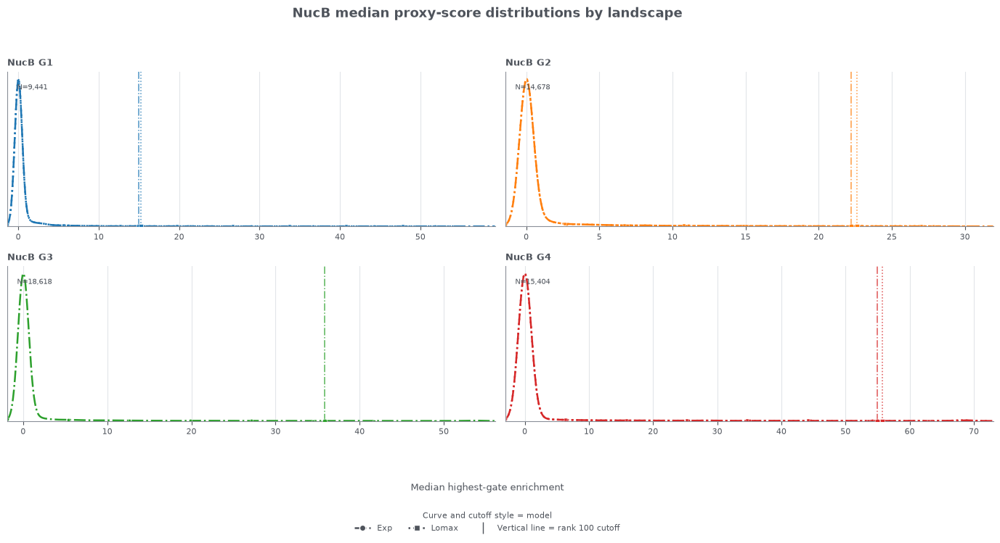

In [18]:
figure_8_3_nuc = figure_functionality_distributions(
    inventory,
    functionality_scores,
    protein_family="nuc",
    top_k=MAIN_K,
)
display(figure_8_3_nuc)
save_figure(
    figure_8_3_nuc,
    FIGURE_DIR,
    "figure8_nucb_functionality",
)
plt.close(figure_8_3_nuc)

## Figure 9: Decision-relative proxy score and uncertainty

For candidate $i$, define

$$
x_i=\frac{m_i-m_{(100)}}{S_{\mathrm{run}}},
\qquad
y_i=\frac{Q_{0.95}(z_i)-Q_{0.05}(z_i)}{S_{\mathrm{run}}},
$$

where $m_i$ is the median count-proxy score, $m_{(100)}$ is the score at fixed reference rank 100, and $S_{\mathrm{run}}$ is the top-1,000 median-score IQR. Thus $x=0$ is the fixed top-100 boundary. Blue filled points are fixed top-100 members; orange open points are outside variants with at least 1% sampled top-100 inclusion probability.

Associations are computed within each analysis and displayed from the generated mechanism tables. They are descriptive under the joint HMC posterior-predictive distribution; they do not establish that score location causes uncertainty.

### Figure 9.1: PDZ analyses

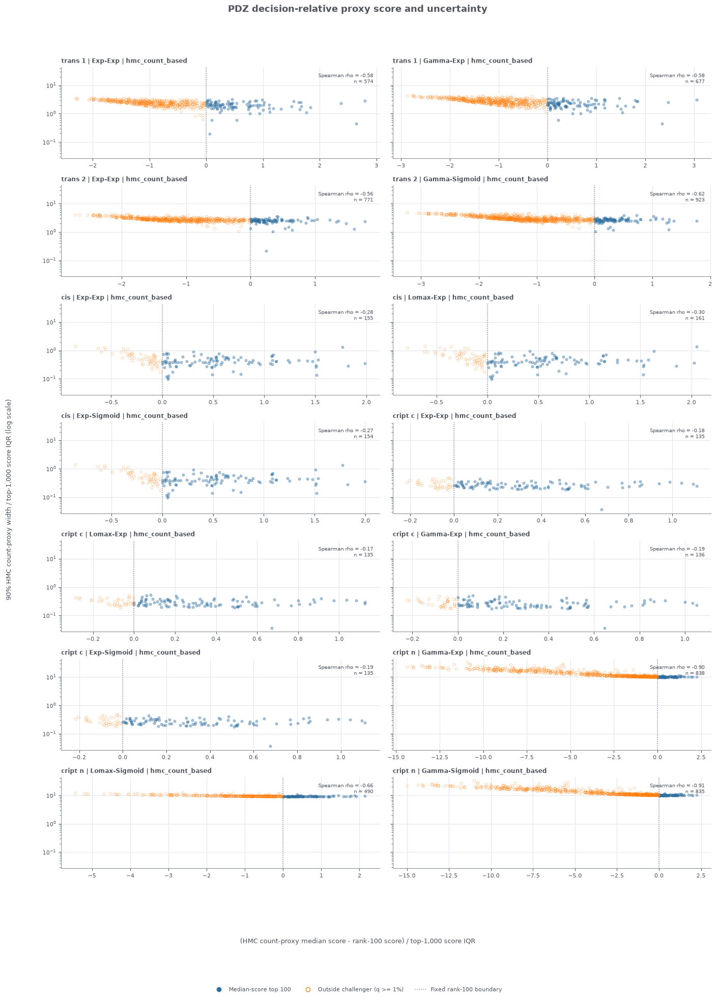

In [19]:
figure_9_1_pdz = figure_fitness_uncertainty_by_analysis(
    mechanism_tables,
    protein_family="pdz",
)
display(figure_9_1_pdz)
save_figure(
    figure_9_1_pdz,
    FIGURE_DIR,
    "figure9_pdz_fitness_uncertainty",
)
plt.close(figure_9_1_pdz)

### Figure 9.2: TrpB analyses

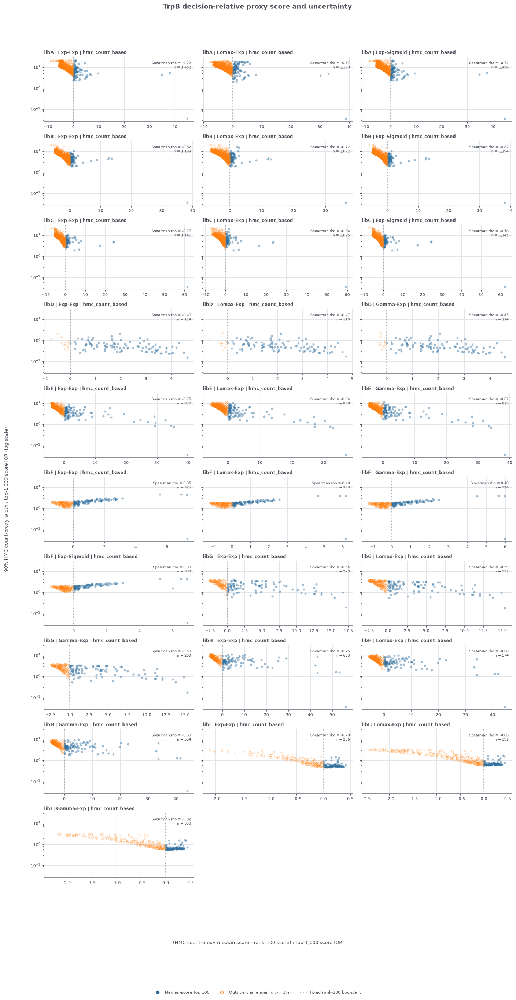

In [20]:
figure_9_2_trpb = figure_fitness_uncertainty_by_analysis(
    mechanism_tables,
    protein_family="trpb",
)
display(figure_9_2_trpb)
save_figure(
    figure_9_2_trpb,
    FIGURE_DIR,
    "figure9_trpb_fitness_uncertainty",
)
plt.close(figure_9_2_trpb)

### Figure 9.3: NucB analyses

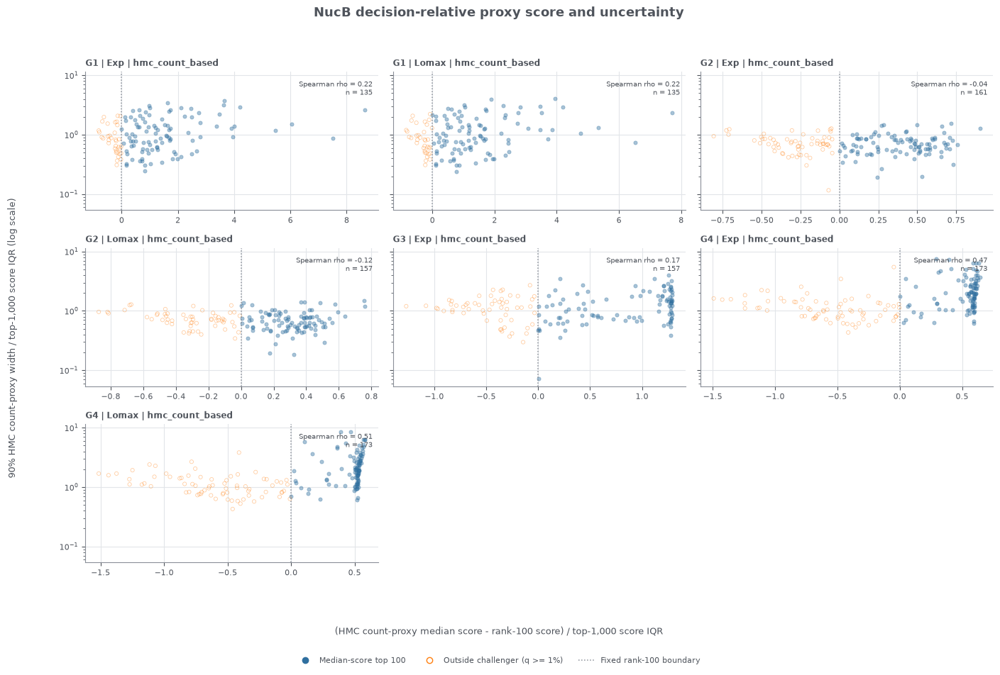

In [21]:
figure_9_3_nuc = figure_fitness_uncertainty_by_analysis(
    mechanism_tables,
    protein_family="nuc",
)
display(figure_9_3_nuc)
save_figure(
    figure_9_3_nuc,
    FIGURE_DIR,
    "figure9_nucb_fitness_uncertainty",
)
plt.close(figure_9_3_nuc)

## Figure 10: Per-analysis summary of top-100 uncertainty

Each row is one analysis and uses the same primary cohort as Figure 9. The four columns relate input support, output abundance, and decision margin to normalized count-proxy uncertainty and top-100 inclusion probability. Filled blue points are fixed top-100 members; open orange points are outside challengers. Row labels report top-100 instability and challenger count.

The supporting diagnostics report associations separately for the full primary cohort, fixed top-100 members, and outside challengers, including a rank-residual partial Spearman adjusted for input support. These quantities are descriptive: variants share HMC posterior-predictive draws, output abundance is fitness-dependent, and multiple fitted models of one landscape share observed counts.

### Figure 10.1: PDZ analyses

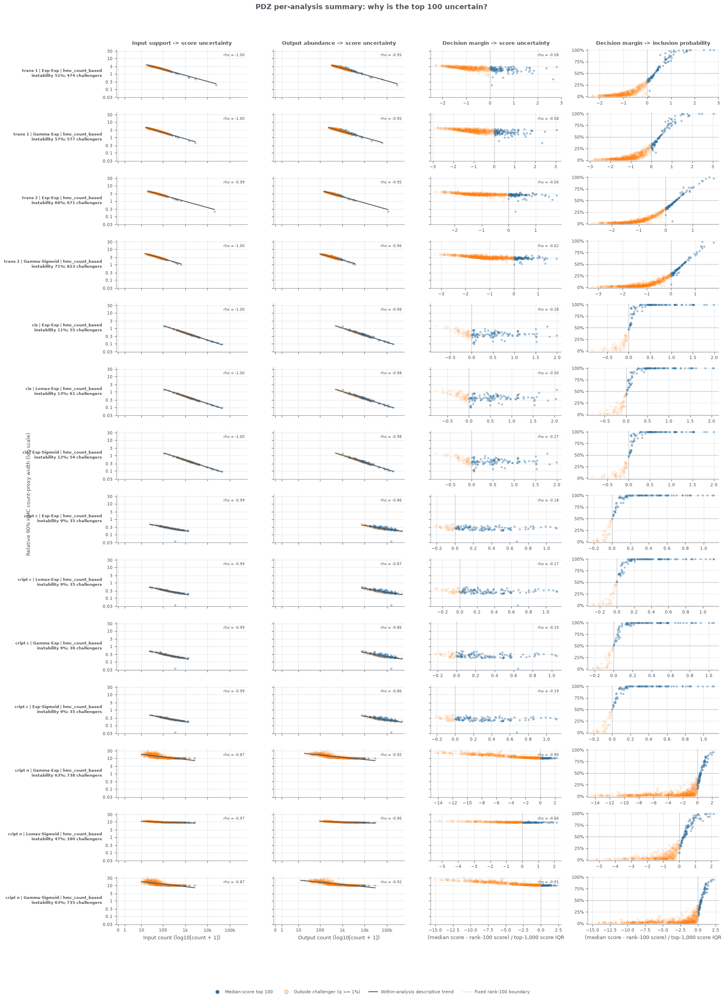

In [22]:
from figures import figure_summary_why_by_analysis

figure_10_1_pdz = figure_summary_why_by_analysis(
    mechanism_tables,
    protein_family="pdz",
)
display(figure_10_1_pdz)
save_figure(
    figure_10_1_pdz,
    FIGURE_DIR,
    "figure10_pdz_summary_why",
)
plt.close(figure_10_1_pdz)

### Figure 10.2: TrpB analyses

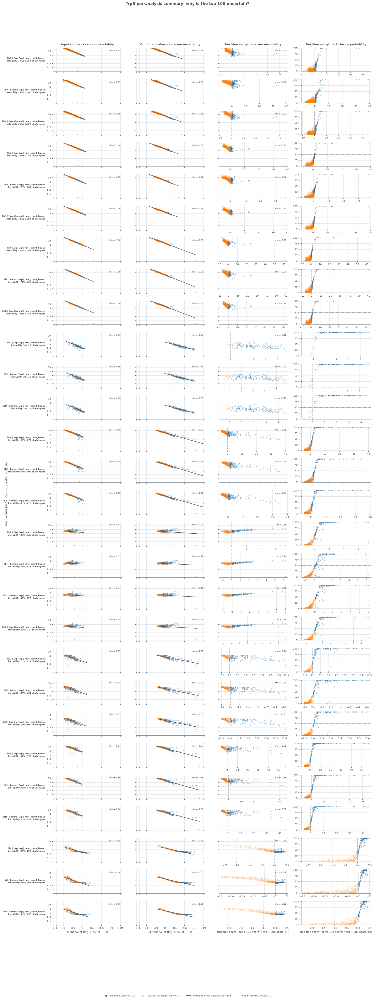

In [23]:
from figures import figure_summary_why_by_analysis

figure_10_2_trpb = figure_summary_why_by_analysis(
    mechanism_tables,
    protein_family="trpb",
)
display(figure_10_2_trpb)
save_figure(
    figure_10_2_trpb,
    FIGURE_DIR,
    "figure10_trpb_summary_why",
)
plt.close(figure_10_2_trpb)

### Figure 10.3: NucB analyses

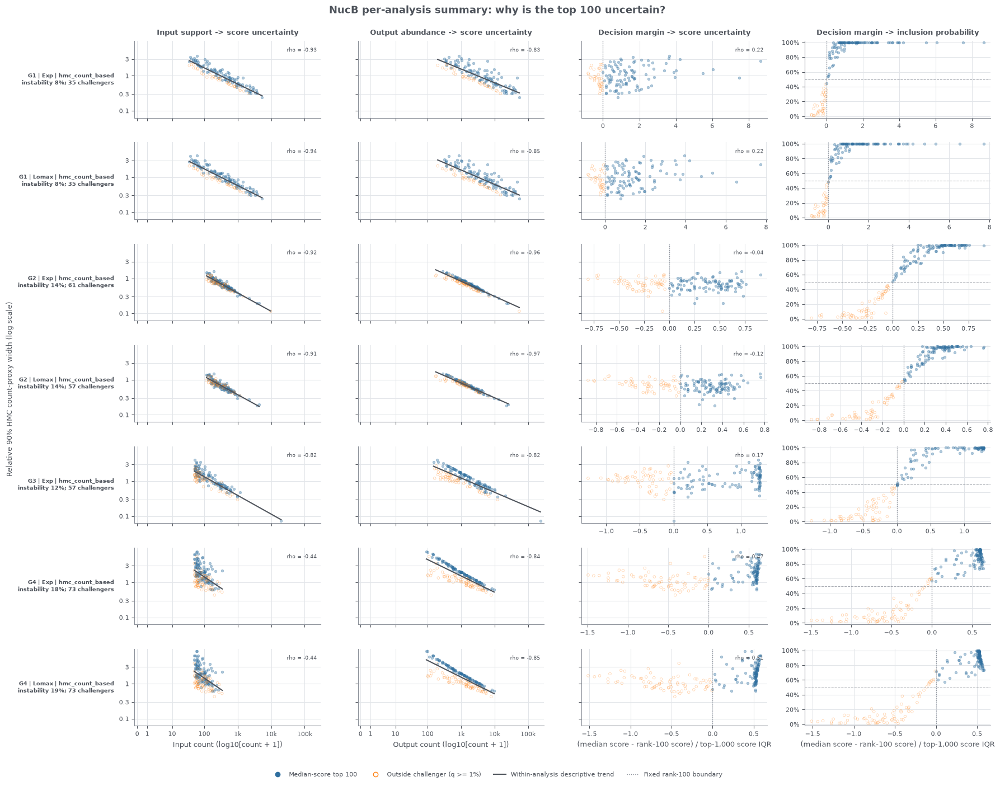

In [24]:
from figures import figure_summary_why_by_analysis

figure_10_3_nuc = figure_summary_why_by_analysis(
    mechanism_tables,
    protein_family="nuc",
)
display(figure_10_3_nuc)
save_figure(
    figure_10_3_nuc,
    FIGURE_DIR,
    "figure10_nucb_summary_why",
)
plt.close(figure_10_3_nuc)

### NucB eligibility and interpretation audit

NucB highest-gate enrichment uses all fitted rows, including source controls, when normalizing input and selected-gate frequencies. Source controls are then excluded from ranking. The tables below compare median count-proxy and reported orderings and separate the Figure 10 decision-margin association into the displayed primary cohort, fixed top-100 members, and outside challengers. `partial_input_adjusted` is a rank-residual partial Spearman adjusted for input support.

In [25]:
nuc_reference_audit = reference_diagnostics[
    reference_diagnostics["protein_family"].eq("nuc")
][
    [
        "fit_id",
        "n_fitted_variants",
        "n_ranking_candidates",
        "n_excluded_from_ranking",
        "all_finite_spearman",
        "positive_reported_spearman",
        "model_reported_top_k_intersection",
        "model_reversed_reported_top_k_intersection",
    ]
]

nuc_mechanism_audit = mechanism_diagnostics[
    mechanism_diagnostics["protein_family"].eq("nuc")
].pivot(
    index="analysis_id",
    columns="stratum",
    values="decision_margin_vs_score_uncertainty_spearman",
).rename_axis(columns=None).reset_index()
partial = mechanism_diagnostics[
    mechanism_diagnostics["protein_family"].eq("nuc")
    & mechanism_diagnostics["stratum"].eq("primary")
][
    [
        "analysis_id",
        "decision_margin_vs_score_uncertainty_partial_spearman_input_adjusted",
    ]
].rename(
    columns={
        "decision_margin_vs_score_uncertainty_partial_spearman_input_adjusted": (
            "partial_input_adjusted"
        )
    }
)

nuc_mechanism_audit = nuc_mechanism_audit.merge(
    partial,
    on="analysis_id",
    validate="one_to_one",
)
display(nuc_reference_audit)
display(nuc_mechanism_audit)

,fit_id,n_fitted_variants,n_ranking_candidates,n_excluded_from_ranking,all_finite_spearman,positive_reported_spearman,model_reported_top_k_intersection,model_reversed_reported_top_k_intersection
42,small-clean_55,10760,9441,1319,0.813544,0.977871,93,0
43,small-clean_56,10760,9441,1319,0.813473,0.978086,93,0
44,small-clean_57,14755,14678,77,0.677050,0.919290,81,0
45,small-clean_58,14755,14678,77,0.677862,0.919491,79,0
46,small-clean_59,18790,18618,172,0.632230,0.960822,68,0
47,small-clean_61,15554,15404,150,0.731312,0.918473,36,0
48,small-clean_62,15554,15404,150,0.730518,0.917703,35,0


,analysis_id,challengers,model_top_k,primary,partial_input_adjusted
0,nuc__nuc-g1__hmc-count-based__exponential__sma...,-0.469188,0.250285,0.219910,0.931133
1,nuc__nuc-g1__hmc-count-based__lomax__small-cle...,-0.350420,0.246229,0.221315,0.926379
2,nuc__nuc-g2__hmc-count-based__exponential__sma...,-0.141089,0.077840,-0.036974,0.231510
3,nuc__nuc-g2__hmc-count-based__lomax__small-cle...,-0.348328,0.051173,-0.124657,-0.002183
4,nuc__nuc-g3__hmc-count-based__exponential__sma...,-0.116930,0.312309,0.166381,0.479235
5,nuc__nuc-g4__hmc-count-based__exponential__sma...,-0.367274,0.270922,0.465415,0.506468
6,nuc__nuc-g4__hmc-count-based__lomax__small-cle...,-0.424010,0.403917,0.511826,0.541214


## Artifact inventory

In [26]:
display(
    inventory[[
        "analysis_id",
        "n_samples",
        "n_fitted_variants",
        "n_variants",
        "n_excluded_from_ranking",
        "artifact_status",
        "warnings",
    ]]
)

,analysis_id,n_samples,n_fitted_variants,n_variants,n_excluded_from_ranking,artifact_status,warnings
0,pdz__pdz-trans-1__hmc-count-based__exponential...,16000,150769,109376,41393,validated,"[""This raw-count approximation does not exactl..."
1,pdz__pdz-trans-1__hmc-count-based__gamma-expon...,16000,150769,109376,41393,validated,"[""This raw-count approximation does not exactl..."
2,pdz__pdz-trans-2__hmc-count-based__exponential...,16000,151624,142251,9373,validated,"[""This raw-count approximation does not exactl..."
3,pdz__pdz-trans-2__hmc-count-based__gamma-sigmo...,16000,151624,142251,9373,validated,"[""This raw-count approximation does not exactl..."
4,pdz__pdz-cis__hmc-count-based__exponential-exp...,16000,10660,9475,1185,validated,"[""This raw-count approximation does not exactl..."
5,pdz__pdz-cis__hmc-count-based__lomax-exponenti...,16000,10660,9475,1185,validated,"[""This raw-count approximation does not exactl..."
6,pdz__pdz-cis__hmc-count-based__exponential-sig...,16000,10660,9475,1185,validated,"[""This raw-count approximation does not exactl..."
7,pdz__pdz-cript-c__hmc-count-based__exponential...,16000,145290,117723,27567,validated,"[""This raw-count approximation does not exactl..."
8,pdz__pdz-cript-c__hmc-count-based__lomax-expon...,24000,145290,117723,27567,validated,"[""This raw-count approximation does not exactl..."
9,pdz__pdz-cript-c__hmc-count-based__gamma-expon...,24000,145290,117723,27567,validated,"[""This raw-count approximation does not exactl..."


## Figure 11: Joint count support and count-proxy uncertainty

Each small corner is one analysis. Within each horizontal block, each column is one landscape and its fitted models are stacked vertically; blocks contain at most three landscapes so the corner panels remain readable. The plotted variant cohort is the median-score top 100, outside variants with at least 1% sampled top-100 inclusion probability, and eligible reported top-1,000 context. Diagonal panels show black KDEs in the displayed coordinates for observed input count, observed output count, and relative HMC count-proxy uncertainty. Lower-triangle panels show all three pairwise relationships: tiny gray points are reported-context-only variants, small filled blue circles are median-score top-100 variants, and small hollow orange circles are challengers. Upper-triangle cells report within-analysis Spearman correlations. Counts use $\log_{10}(n+1)$ so zeros are retained. Relative score uncertainty is the 90% count-proxy width divided by the run score IQR and is displayed on a log scale. Axis limits are shared within each protein family. The sampled proxy distributions combine posterior parameter uncertainty and stochastic predictive-count variability.

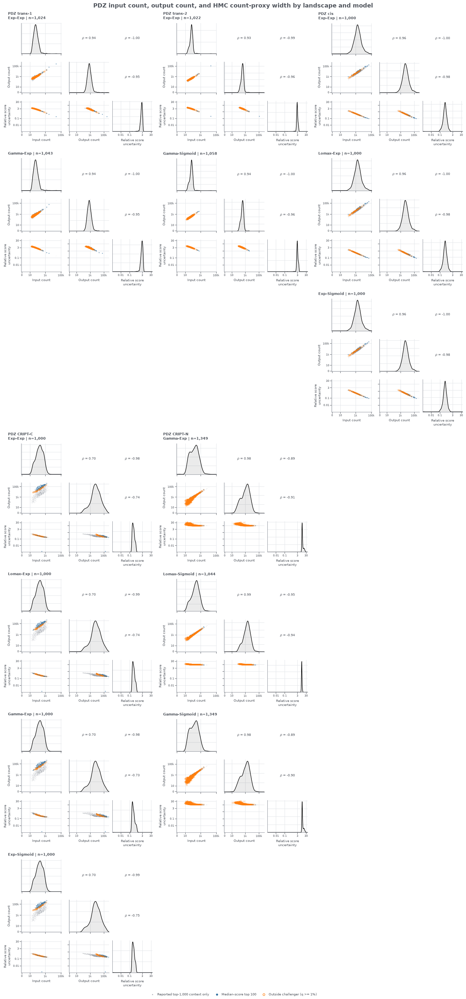

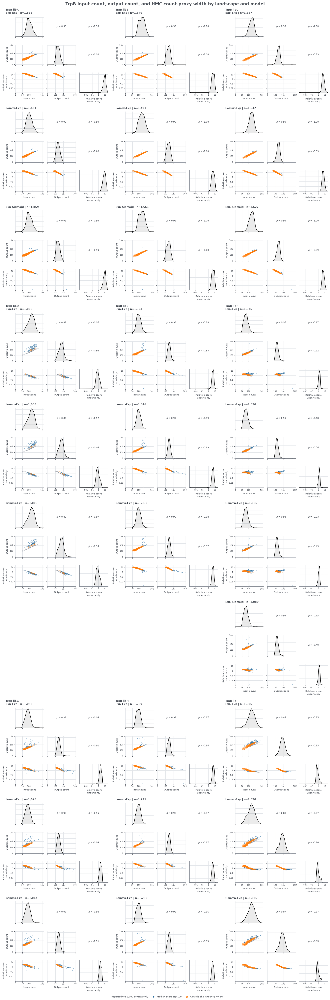

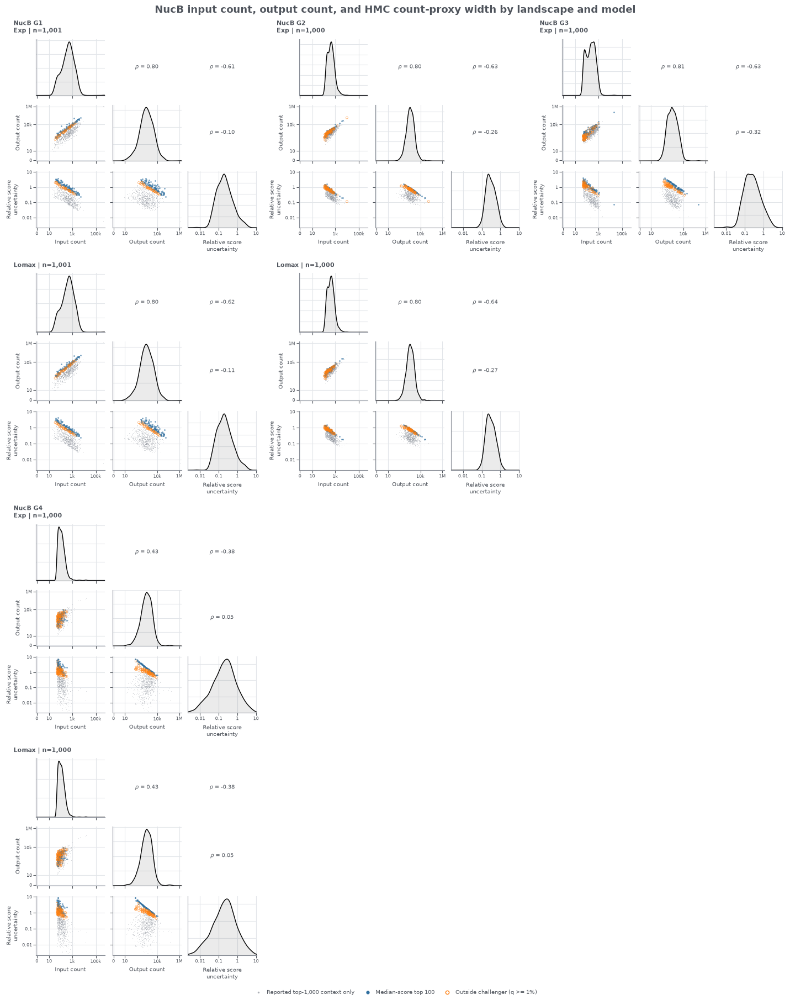

In [5]:
from figures import FAMILY_FILE_STEMS, figure_count_score_corner_by_analysis

figure_11_tables = load_mechanism_tables(TABLE_DIR)
figure_11_families = inventory["protein_family"].drop_duplicates().tolist()
for family in figure_11_families:
    figure_11 = figure_count_score_corner_by_analysis(
        figure_11_tables,
        protein_family=family,
    )
    display(figure_11)
    save_figure(
        figure_11,
        FIGURE_DIR,
        f"figure11_{FAMILY_FILE_STEMS[family]}_count_score_corner",
    )
    plt.close(figure_11)